
# Phase 10D — Bootstrap Uncertainty on Context-Cube Spectra — revised

Input: `phase8R_wired_repeated_raw_results.csv`.

For each query, this notebook bootstraps the repeated measurements **within each mask** and estimates uncertainty for:

\[
\text{Walsh coefficients},
\quad
\text{energy by order},
\quad
\text{bit sensitivities},
\quad
f^\top Lf,
\quad
\text{heat-flow roughness}.
\]

This revision adds two diagnostics that are important when a query is sparse or nearly degenerate:

\[
P_{\rm boot}(F^{(b)}\equiv 0)
\]

and

\[
P_{\rm boot}\!\left(E_{\rm nonDC}^{(b)}>0\right).
\]

It also reports an estimated **measurement-noise contribution** to the observed Laplacian energy. This matters because quadratic quantities such as \(f^\top Lf\) are biased upward by finite-repeat noise.


In [1]:

from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "phase8R_wired_repeated_raw_results.csv"
SIGNAL_COL = "quality"

# Use 200 for a quick pilot, 1000+ for the final analysis.
N_BOOT = 1000
CI_LEVEL = 0.95
RANDOM_SEED = 20260925

# Numerical threshold for a bootstrap surface to count as non-degenerate.
DEGENERATE_TOL = 1e-12

HEAT_T = np.linspace(0.0, 1.5, 13)

rng = np.random.default_rng(RANDOM_SEED)

raw = pd.read_csv(DATA_PATH)

required = {"query_id", "mask", "repeat", SIGNAL_COL}
missing = required - set(raw.columns)
if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

raw["mask"] = pd.to_numeric(raw["mask"], errors="raise").astype(int)
raw["repeat"] = pd.to_numeric(raw["repeat"], errors="raise").astype(int)
raw[SIGNAL_COL] = pd.to_numeric(raw[SIGNAL_COL], errors="coerce")
raw = raw[raw[SIGNAL_COL].notna()].copy()

N_STATES = int(raw["mask"].max()) + 1
N_BITS = int(round(math.log2(N_STATES)))
if 2**N_BITS != N_STATES:
    raise ValueError("Mask range is not a complete Boolean cube.")

print("N_BITS:", N_BITS)
print("N_STATES:", N_STATES)
print("queries:", raw["query_id"].nunique())
print("repeats found:", sorted(raw["repeat"].unique()))


N_BITS: 6
N_STATES: 64
queries: 3
repeats found: [0, 1, 2, 3]


In [2]:

coverage = (
    raw.groupby(["query_id", "mask"])
    .agg(n=("repeat", "nunique"))
    .reset_index()
)

coverage_summary = (
    coverage.groupby("query_id")
    .agg(
        n_masks=("mask", "nunique"),
        min_repeats=("n", "min"),
        median_repeats=("n", "median"),
        max_repeats=("n", "max"),
    )
    .reset_index()
)

coverage_summary["complete_cube"] = coverage_summary["n_masks"] == N_STATES
coverage_summary["bootstrap_ready"] = (
    coverage_summary["complete_cube"]
    & (coverage_summary["min_repeats"] >= 2)
)

display(coverage_summary)

ready_queries = coverage_summary.loc[
    coverage_summary["bootstrap_ready"], "query_id"
].tolist()

if not ready_queries:
    raise RuntimeError(
        "No complete query has >=2 valid repeats per mask. Run Phase 8R first."
    )

print("bootstrap-ready:", ready_queries)


,query_id,n_masks,min_repeats,median_repeats,max_repeats,complete_cube,bootstrap_ready
0,5a855b5c5542997b5ce3ffeb,64,4,4.0,4,True,True
1,5a860aa6554299211dda2a45,64,4,4.0,4,True,True
2,5a90b1a15542990a984936ab,64,4,4.0,4,True,True


bootstrap-ready: ['5a855b5c5542997b5ce3ffeb', '5a860aa6554299211dda2a45', '5a90b1a15542990a984936ab']


In [3]:

def fwht(a):
    a = np.asarray(a, dtype=float).copy()
    h = 1
    n = len(a)
    while h < n:
        for i in range(0, n, 2*h):
            x = a[i:i+h].copy()
            y = a[i+h:i+2*h].copy()
            a[i:i+h] = x + y
            a[i+h:i+2*h] = x - y
        h *= 2
    return a

def popcount(x):
    return int(x).bit_count()

def walsh_coeff(f):
    return fwht(np.asarray(f, float)) / len(f)

ORDER_INDEX = {
    k: np.array([i for i in range(N_STATES) if popcount(i) == k], dtype=int)
    for k in range(N_BITS + 1)
}

def walsh_energy(coeff):
    return np.array([
        np.sum(coeff[ORDER_INDEX[k]]**2)
        for k in range(N_BITS + 1)
    ], dtype=float)

def hypercube_laplacian(d):
    n = 2**d
    A = np.zeros((n, n), dtype=float)
    for x in range(n):
        for bit in range(d):
            A[x, x ^ (1 << bit)] = 1.0
    return np.diag(A.sum(axis=1)) - A

L = hypercube_laplacian(N_BITS)
eigvals, eigvecs = np.linalg.eigh(L)

expected = []
for k in range(N_BITS + 1):
    expected.extend([2*k] * math.comb(N_BITS, k))
assert np.allclose(eigvals, expected, atol=1e-10)

def lap_energy(f):
    f = np.asarray(f, float)
    return float(f @ L @ f)

def heat_flow(f, t):
    f = np.asarray(f, float)
    return eigvecs @ (np.exp(-t * eigvals) * (eigvecs.T @ f))

def heat_roughness(f, t):
    ft = heat_flow(f, t)
    return float(ft @ L @ ft)

def bit_sensitivity(f):
    f = np.asarray(f, float)
    signed, abs_mean, rms = [], [], []
    for bit in range(N_BITS):
        diffs = []
        for x in range(N_STATES):
            if ((x >> bit) & 1) == 0:
                diffs.append(f[x | (1 << bit)] - f[x])
        diffs = np.asarray(diffs, float)
        signed.append(diffs.mean())
        abs_mean.append(np.abs(diffs).mean())
        rms.append(np.sqrt(np.mean(diffs**2)))
    return np.array(signed), np.array(abs_mean), np.array(rms)



## Bootstrap

For every mask \(S\), resample its observed repeats with replacement and average them.  
One bootstrap draw therefore creates a complete resampled surface \(F^{(b)}(S)\).


In [4]:

alpha = (1.0 - CI_LEVEL) / 2.0

def ci(a, axis=0):
    a = np.asarray(a)
    return (
        np.nanquantile(a, alpha, axis=axis),
        np.nanquantile(a, 0.5, axis=axis),
        np.nanquantile(a, 1.0-alpha, axis=axis),
    )

def query_mask_samples(df_query):
    samples = {}
    for mask in range(N_STATES):
        x = (
            df_query.loc[df_query["mask"] == mask, SIGNAL_COL]
            .dropna()
            .to_numpy(float)
        )
        if len(x) < 2:
            raise ValueError(f"mask {mask}: only {len(x)} valid repeats")
        samples[mask] = x
    return samples

def mean_surface(samples):
    return np.array([samples[m].mean() for m in range(N_STATES)], dtype=float)

def bootstrap_surface(samples):
    f = np.empty(N_STATES, dtype=float)
    for m in range(N_STATES):
        x = samples[m]
        f[m] = rng.choice(x, size=len(x), replace=True).mean()
    return f


In [5]:

def mean_measurement_variance(samples):
    """
    Estimated variance of the per-mask sample mean due to repeat noise:
        Var(mean_S) ~= s_S^2 / R_S
    """
    out = np.empty(N_STATES, dtype=float)
    for m in range(N_STATES):
        x = np.asarray(samples[m], dtype=float)
        if len(x) < 2:
            out[m] = np.nan
        else:
            out[m] = np.var(x, ddof=1) / len(x)
    return out

def laplacian_noise_bias_estimate(samples):
    """
    On the d-dimensional hypercube:
        f^T L f = sum_{undirected edges {u,v}} (f_u-f_v)^2.

    Independent measurement noise in the estimated per-mask means contributes
        Var(mean_u) + Var(mean_v)
    on each edge. Every vertex belongs to d edges, hence the estimated total
    quadratic noise contribution is:
        d * sum_S Var(mean_S).
    """
    var_mean = mean_measurement_variance(samples)
    return float(N_BITS * np.nansum(var_mean))


In [6]:

summary_rows = []
order_rows = []
bit_rows = []
coeff_rows = []
heat_rows = []
degeneracy_rows = []

for iq, query_id in enumerate(ready_queries, start=1):
    print(f"[{iq}/{len(ready_queries)}] {query_id}")

    dq = raw[raw["query_id"] == query_id]
    samples = query_mask_samples(dq)
    f_hat = mean_surface(samples)

    c_hat = walsh_coeff(f_hat)
    e_hat = walsh_energy(c_hat)
    nd_hat = e_hat[1:].sum()

    signed_hat, abs_hat, rms_hat = bit_sensitivity(f_hat)
    lap_hat = lap_energy(f_hat)
    lap_noise_bias = laplacian_noise_bias_estimate(samples)
    lap_noise_corrected = lap_hat - lap_noise_bias

    heat_hat = np.array([heat_roughness(f_hat, t) for t in HEAT_T])

    boot_coeff = np.empty((N_BOOT, N_STATES))
    boot_energy = np.empty((N_BOOT, N_BITS+1))
    boot_frac = np.full((N_BOOT, N_BITS+1), np.nan)
    boot_signed = np.empty((N_BOOT, N_BITS))
    boot_abs = np.empty((N_BOOT, N_BITS))
    boot_rms = np.empty((N_BOOT, N_BITS))
    boot_lap = np.empty(N_BOOT)
    boot_heat = np.empty((N_BOOT, len(HEAT_T)))

    boot_all_zero = np.zeros(N_BOOT, dtype=bool)
    boot_interaction_nondegenerate = np.zeros(N_BOOT, dtype=bool)
    boot_non_dc_energy = np.empty(N_BOOT, dtype=float)

    for b in range(N_BOOT):
        fb = bootstrap_surface(samples)
        cb = walsh_coeff(fb)
        eb = walsh_energy(cb)
        nd = float(eb[1:].sum())

        boot_coeff[b] = cb
        boot_energy[b] = eb
        boot_non_dc_energy[b] = nd

        boot_all_zero[b] = bool(np.max(np.abs(fb)) <= DEGENERATE_TOL)
        boot_interaction_nondegenerate[b] = bool(nd > DEGENERATE_TOL)

        # Conditional normalization: only non-degenerate bootstrap surfaces
        # contribute to the normalized interaction-spectrum CI.
        if nd > DEGENERATE_TOL:
            boot_frac[b, 1:] = eb[1:] / nd

        s, a, r = bit_sensitivity(fb)
        boot_signed[b] = s
        boot_abs[b] = a
        boot_rms[b] = r
        boot_lap[b] = lap_energy(fb)
        boot_heat[b] = [heat_roughness(fb, t) for t in HEAT_T]

    lap_lo, lap_med, lap_hi = ci(boot_lap)
    nd_lo, nd_med, nd_hi = ci(boot_non_dc_energy)

    p_all_zero = float(np.mean(boot_all_zero))
    p_nondegenerate = float(np.mean(boot_interaction_nondegenerate))
    n_nondegenerate = int(np.sum(boot_interaction_nondegenerate))

    summary_rows.append({
        "query_id": query_id,
        "mean_F": float(f_hat.mean()),
        "std_across_masks": float(f_hat.std(ddof=0)),
        "F_empty": float(f_hat[0]),
        "F_full": float(f_hat[-1]),
        "laplacian_energy": lap_hat,
        "laplacian_ci_low": float(lap_lo),
        "laplacian_ci_median": float(lap_med),
        "laplacian_ci_high": float(lap_hi),
        "laplacian_noise_bias_est": lap_noise_bias,
        "laplacian_noise_corrected_est": lap_noise_corrected,
        "non_dc_energy": float(nd_hat),
        "non_dc_energy_ci_low": float(nd_lo),
        "non_dc_energy_ci_median": float(nd_med),
        "non_dc_energy_ci_high": float(nd_hi),
        "p_boot_all_zero": p_all_zero,
        "p_boot_interaction_nondegenerate": p_nondegenerate,
        "n_boot_interaction_nondegenerate": n_nondegenerate,
        "min_repeats_per_mask": min(len(x) for x in samples.values()),
        "max_repeats_per_mask": max(len(x) for x in samples.values()),
    })

    degeneracy_rows.append({
        "query_id": query_id,
        "n_boot": N_BOOT,
        "n_all_zero": int(np.sum(boot_all_zero)),
        "p_all_zero": p_all_zero,
        "n_interaction_nondegenerate": n_nondegenerate,
        "p_interaction_nondegenerate": p_nondegenerate,
        "conditioning_note": (
            "normalized interaction-energy CIs are conditional on "
            "non-DC energy > DEGENERATE_TOL"
        ),
    })

    e_lo, e_med, e_hi = ci(boot_energy, axis=0)
    f_lo, f_med, f_hi = ci(boot_frac, axis=0)

    for k in range(N_BITS+1):
        order_rows.append({
            "query_id": query_id,
            "order": k,
            "energy": float(e_hat[k]),
            "energy_ci_low": float(e_lo[k]),
            "energy_ci_median": float(e_med[k]),
            "energy_ci_high": float(e_hi[k]),
            "non_dc_fraction": (
                float(e_hat[k]/nd_hat)
                if k > 0 and nd_hat > DEGENERATE_TOL else np.nan
            ),
            "non_dc_fraction_ci_low": float(f_lo[k]) if k > 0 else np.nan,
            "non_dc_fraction_ci_median": float(f_med[k]) if k > 0 else np.nan,
            "non_dc_fraction_ci_high": float(f_hi[k]) if k > 0 else np.nan,
            "n_boot_fraction_valid": n_nondegenerate if k > 0 else 0,
            "p_boot_fraction_valid": p_nondegenerate if k > 0 else np.nan,
        })

    s_lo, s_med, s_hi = ci(boot_signed, axis=0)
    a_lo, a_med, a_hi = ci(boot_abs, axis=0)
    r_lo, r_med, r_hi = ci(boot_rms, axis=0)

    for bit in range(N_BITS):
        bit_rows.append({
            "query_id": query_id,
            "bit": bit,
            "mean_signed": float(signed_hat[bit]),
            "mean_signed_ci_low": float(s_lo[bit]),
            "mean_signed_ci_median": float(s_med[bit]),
            "mean_signed_ci_high": float(s_hi[bit]),
            "mean_abs": float(abs_hat[bit]),
            "mean_abs_ci_low": float(a_lo[bit]),
            "mean_abs_ci_median": float(a_med[bit]),
            "mean_abs_ci_high": float(a_hi[bit]),
            "rms": float(rms_hat[bit]),
            "rms_ci_low": float(r_lo[bit]),
            "rms_ci_median": float(r_med[bit]),
            "rms_ci_high": float(r_hi[bit]),
        })

    c_lo, c_med, c_hi = ci(boot_coeff, axis=0)
    for freq_mask in range(N_STATES):
        coeff_rows.append({
            "query_id": query_id,
            "frequency_mask": freq_mask,
            "order": popcount(freq_mask),
            "coefficient": float(c_hat[freq_mask]),
            "ci_low": float(c_lo[freq_mask]),
            "ci_median": float(c_med[freq_mask]),
            "ci_high": float(c_hi[freq_mask]),
            "ci_excludes_zero": bool(
                (c_lo[freq_mask] > 0) or (c_hi[freq_mask] < 0)
            ),
        })

    h_lo, h_med, h_hi = ci(boot_heat, axis=0)
    for j, t in enumerate(HEAT_T):
        heat_rows.append({
            "query_id": query_id,
            "t": float(t),
            "roughness": float(heat_hat[j]),
            "ci_low": float(h_lo[j]),
            "ci_median": float(h_med[j]),
            "ci_high": float(h_hi[j]),
        })

summary_df = pd.DataFrame(summary_rows)
order_df = pd.DataFrame(order_rows)
bits_df = pd.DataFrame(bit_rows)
coeff_df = pd.DataFrame(coeff_rows)
heat_df = pd.DataFrame(heat_rows)
degeneracy_df = pd.DataFrame(degeneracy_rows)

display(summary_df)
display(degeneracy_df)
display(order_df.head(20))
display(bits_df.head(20))


[1/3] 5a855b5c5542997b5ce3ffeb


C:\Users\Mauro\AppData\Local\Programs\Python\Python311\Lib\site-packages\numpy\lib\nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


[2/3] 5a860aa6554299211dda2a45
[3/3] 5a90b1a15542990a984936ab


,query_id,mean_F,std_across_masks,F_empty,F_full,laplacian_energy,laplacian_ci_low,laplacian_ci_median,laplacian_ci_high,laplacian_noise_bias_est,laplacian_noise_corrected_est,non_dc_energy,non_dc_energy_ci_low,non_dc_energy_ci_median,non_dc_energy_ci_high,p_boot_all_zero,p_boot_interaction_nondegenerate,n_boot_interaction_nondegenerate,min_repeats_per_mask,max_repeats_per_mask
0,5a855b5c5542997b5ce3ffeb,0.058464,0.078780,0.0,0.117647,2.095766,1.923183,3.068274,4.616324,1.378935,0.716832,0.006206,0.005390,0.008664,0.013201,0.000,1.000,1000,4,4
1,5a860aa6554299211dda2a45,0.465402,0.248637,0.0,0.181818,21.316432,23.026597,27.569099,32.451504,8.494055,12.822377,0.061820,0.067198,0.078077,0.089521,0.000,1.000,1000,4,4
2,5a90b1a15542990a984936ab,0.007812,0.062010,0.0,0.000000,1.500000,0.000000,1.500000,6.000000,0.500000,1.000000,0.003845,0.000000,0.003845,0.015381,0.054,0.946,946,4,4


,query_id,n_boot,n_all_zero,p_all_zero,n_interaction_nondegenerate,p_interaction_nondegenerate,conditioning_note
0,5a855b5c5542997b5ce3ffeb,1000,0,0.000,1000,1.000,normalized interaction-energy CIs are conditio...
1,5a860aa6554299211dda2a45,1000,0,0.000,1000,1.000,normalized interaction-energy CIs are conditio...
2,5a90b1a15542990a984936ab,1000,54,0.054,946,0.946,normalized interaction-energy CIs are conditio...


,query_id,order,energy,energy_ci_low,energy_ci_median,energy_ci_high,non_dc_fraction,non_dc_fraction_ci_low,non_dc_fraction_ci_median,non_dc_fraction_ci_high,n_boot_fraction_valid,p_boot_fraction_valid
0,5a855b5c5542997b5ce3ffeb,0,0.003418,2.112099e-03,0.003375,0.005039,NaN,NaN,NaN,NaN,0,NaN
1,5a855b5c5542997b5ce3ffeb,1,0.001682,8.888253e-04,0.001859,0.003232,0.271030,0.132844,0.211580,0.304131,1000,1.000
2,5a855b5c5542997b5ce3ffeb,2,0.001209,9.609181e-04,0.001793,0.003148,0.194829,0.132217,0.208618,0.297659,1000,1.000
3,5a855b5c5542997b5ce3ffeb,3,0.001603,1.221968e-03,0.002332,0.004279,0.258244,0.180909,0.274810,0.374821,1000,1.000
4,5a855b5c5542997b5ce3ffeb,4,0.001204,9.142437e-04,0.001777,0.003010,0.193955,0.125060,0.204128,0.292205,1000,1.000
5,5a855b5c5542997b5ce3ffeb,5,0.000402,1.941886e-04,0.000608,0.001330,0.064717,0.021811,0.072646,0.146778,1000,1.000
6,5a855b5c5542997b5ce3ffeb,6,0.000107,5.644429e-07,0.000100,0.000580,0.017224,0.000070,0.011943,0.061637,1000,1.000
7,5a860aa6554299211dda2a45,0,0.216599,1.889208e-01,0.217686,0.249292,NaN,NaN,NaN,NaN,0,NaN
8,5a860aa6554299211dda2a45,1,0.021309,1.474381e-02,0.022815,0.032709,0.344684,0.197281,0.295612,0.391971,1000,1.000
9,5a860aa6554299211dda2a45,2,0.007548,6.500530e-03,0.011371,0.017708,0.122103,0.085953,0.145700,0.218536,1000,1.000


,query_id,bit,mean_signed,mean_signed_ci_low,mean_signed_ci_median,mean_signed_ci_high,mean_abs,mean_abs_ci_low,mean_abs_ci_median,mean_abs_ci_high,rms,rms_ci_low,rms_ci_median,rms_ci_high
0,5a855b5c5542997b5ce3ffeb,0,0.072725,0.047380,0.072882,0.096232,0.087404,0.068726,0.091519,0.114623,0.120145,0.107366,0.139465,0.174389
1,5a855b5c5542997b5ce3ffeb,1,0.013051,-0.010334,0.012903,0.036369,0.066420,0.053102,0.073773,0.098082,0.101069,0.090102,0.122397,0.161316
2,5a855b5c5542997b5ce3ffeb,2,-0.014632,-0.039838,-0.014679,0.009512,0.077595,0.065374,0.085523,0.109258,0.115826,0.104117,0.135160,0.170461
3,5a855b5c5542997b5ce3ffeb,3,0.003453,-0.022233,0.003393,0.028620,0.062846,0.053972,0.072262,0.092945,0.086893,0.082529,0.111476,0.144520
4,5a855b5c5542997b5ce3ffeb,4,0.013389,-0.012826,0.012274,0.039411,0.070357,0.059553,0.081853,0.103120,0.107425,0.098329,0.128775,0.163340
5,5a855b5c5542997b5ce3ffeb,5,0.029391,0.004103,0.029231,0.055323,0.066586,0.055430,0.074900,0.098467,0.091306,0.083683,0.115127,0.151016
6,5a860aa6554299211dda2a45,0,0.043222,-0.019501,0.043425,0.104814,0.320820,0.287330,0.340858,0.398265,0.355567,0.345223,0.398409,0.451230
7,5a860aa6554299211dda2a45,1,-0.026177,-0.085836,-0.024148,0.040189,0.193791,0.195802,0.243912,0.293857,0.272012,0.274647,0.325691,0.377889
8,5a860aa6554299211dda2a45,2,-0.022119,-0.084522,-0.020546,0.041602,0.258929,0.242779,0.295353,0.349541,0.335483,0.328065,0.380131,0.431110
9,5a860aa6554299211dda2a45,3,-0.284903,-0.345376,-0.287744,-0.218314,0.336445,0.313398,0.367999,0.423399,0.420433,0.409518,0.457871,0.505504



## How to read the new degeneracy diagnostics

For a sparse query, a normalized spectrum can look deceptively stable even when many bootstrap draws contain almost no signal.

Therefore always read the order spectrum together with:

\[
P_{\rm boot}(F^{(b)}\equiv0)
\]

and

\[
P_{\rm boot}(E_{\rm nonDC}^{(b)}>0).
\]

The `non_dc_fraction` confidence intervals are now explicitly **conditional on the bootstrap surface being interaction-nondegenerate**.

The notebook also estimates the finite-repeat noise contribution to Laplacian energy:

\[
\widehat{\mathrm{bias}}_{\rm noise}
=
d\sum_S \widehat{\mathrm{Var}}(\bar F_S),
\]

because every vertex of \(Q_d\) belongs to \(d\) undirected edges. The field
`laplacian_noise_corrected_est` is

\[
f^\top Lf-\widehat{\mathrm{bias}}_{\rm noise}.
\]

This correction is diagnostic rather than a guarantee of an unbiased finite-sample CI.


In [7]:

bits_df["stable_direction"] = np.where(
    bits_df["mean_signed_ci_low"] > 0,
    "positive",
    np.where(
        bits_df["mean_signed_ci_high"] < 0,
        "negative",
        "uncertain"
    )
)

display(
    bits_df[
        [
            "query_id","bit","mean_signed",
            "mean_signed_ci_low","mean_signed_ci_high",
            "stable_direction"
        ]
    ]
)


,query_id,bit,mean_signed,mean_signed_ci_low,mean_signed_ci_high,stable_direction
0,5a855b5c5542997b5ce3ffeb,0,0.072725,0.047380,0.096232,positive
1,5a855b5c5542997b5ce3ffeb,1,0.013051,-0.010334,0.036369,uncertain
2,5a855b5c5542997b5ce3ffeb,2,-0.014632,-0.039838,0.009512,uncertain
3,5a855b5c5542997b5ce3ffeb,3,0.003453,-0.022233,0.028620,uncertain
4,5a855b5c5542997b5ce3ffeb,4,0.013389,-0.012826,0.039411,uncertain
5,5a855b5c5542997b5ce3ffeb,5,0.029391,0.004103,0.055323,positive
6,5a860aa6554299211dda2a45,0,0.043222,-0.019501,0.104814,uncertain
7,5a860aa6554299211dda2a45,1,-0.026177,-0.085836,0.040189,uncertain
8,5a860aa6554299211dda2a45,2,-0.022119,-0.084522,0.041602,uncertain
9,5a860aa6554299211dda2a45,3,-0.284903,-0.345376,-0.218314,negative


## Plots with 95% bootstrap intervals

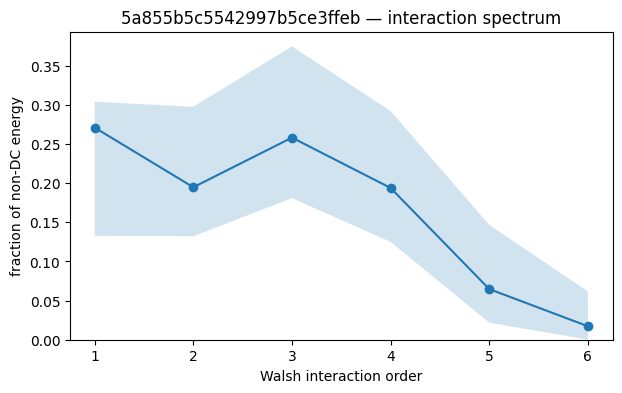

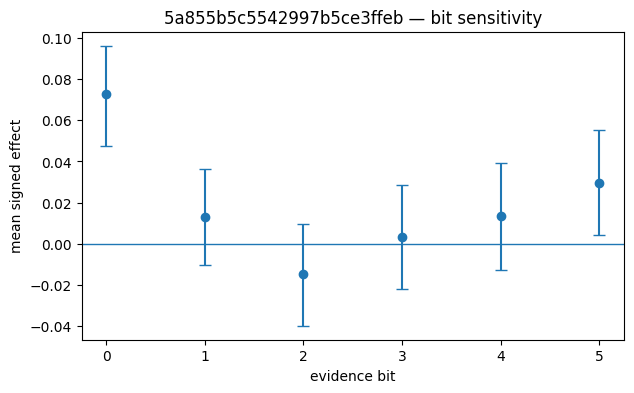

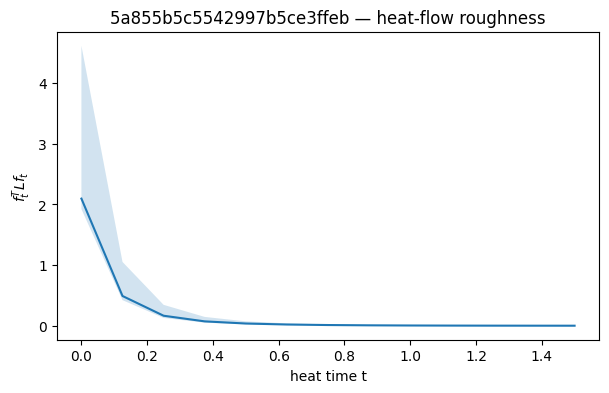

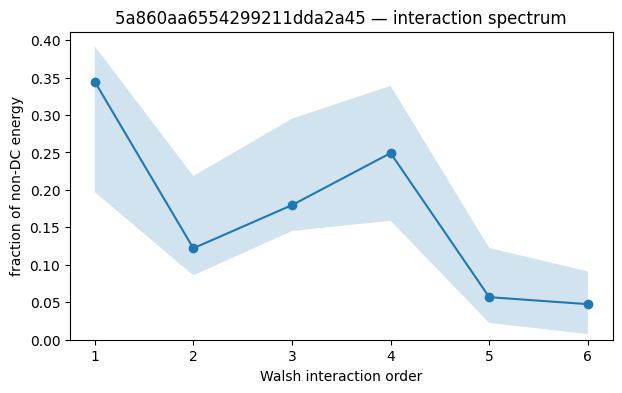

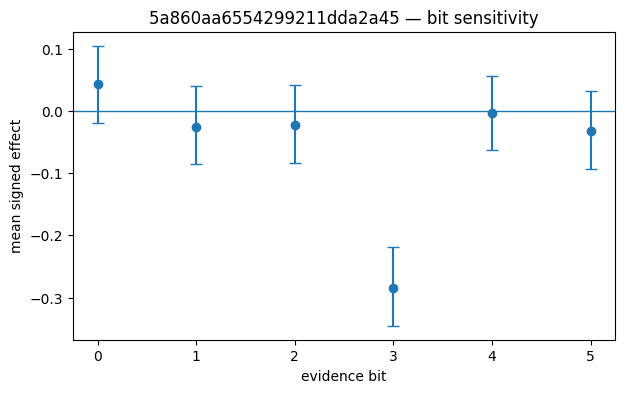

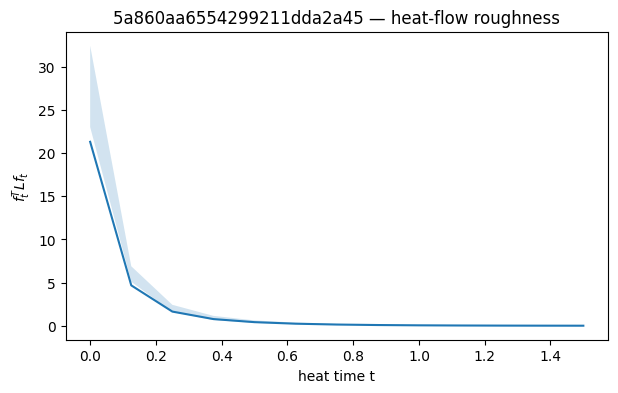

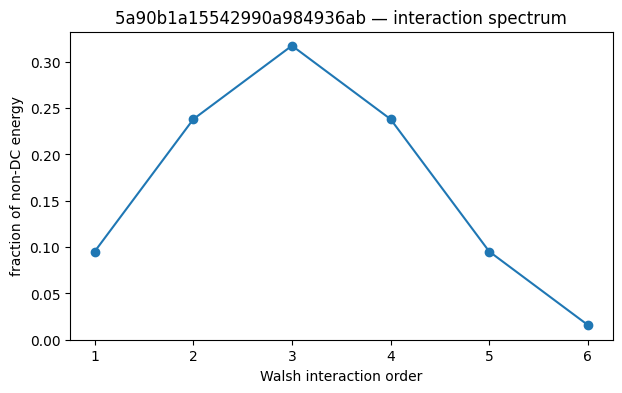

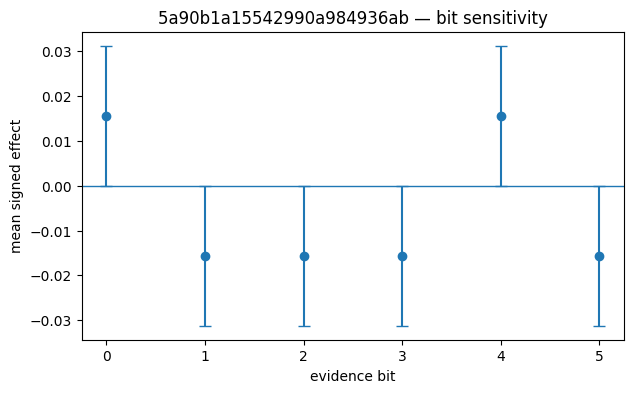

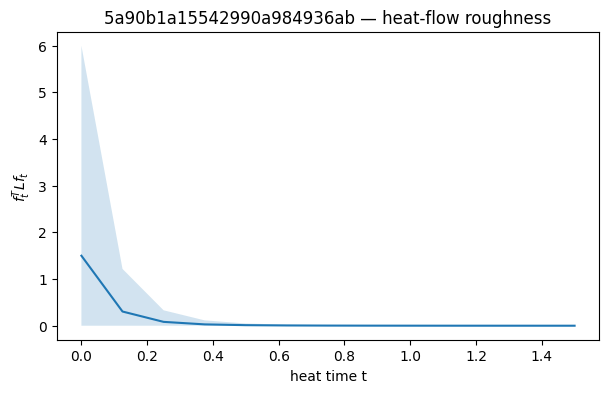

In [8]:

for query_id in ready_queries:
    d = order_df[(order_df["query_id"] == query_id) & (order_df["order"] > 0)]

    plt.figure(figsize=(7,4))
    plt.plot(d["order"], d["non_dc_fraction"], marker="o")
    plt.fill_between(
        d["order"],
        d["non_dc_fraction_ci_low"],
        d["non_dc_fraction_ci_high"],
        alpha=0.2,
    )
    plt.xlabel("Walsh interaction order")
    plt.ylabel("fraction of non-DC energy")
    plt.ylim(bottom=0)
    plt.title(f"{query_id} — interaction spectrum")
    plt.show()

    b = bits_df[bits_df["query_id"] == query_id]
    y = b["mean_signed"].to_numpy(float)
    lo = b["mean_signed_ci_low"].to_numpy(float)
    hi = b["mean_signed_ci_high"].to_numpy(float)

    plt.figure(figsize=(7,4))
    plt.errorbar(
        b["bit"],
        y,
        yerr=np.vstack([y-lo, hi-y]),
        marker="o",
        capsize=4,
        linestyle="none",
    )
    plt.axhline(0.0, linewidth=1)
    plt.xlabel("evidence bit")
    plt.ylabel("mean signed effect")
    plt.title(f"{query_id} — bit sensitivity")
    plt.show()

    h = heat_df[heat_df["query_id"] == query_id]
    plt.figure(figsize=(7,4))
    plt.plot(h["t"], h["roughness"])
    plt.fill_between(h["t"], h["ci_low"], h["ci_high"], alpha=0.2)
    plt.xlabel("heat time t")
    plt.ylabel(r"$f_t^T L f_t$")
    plt.title(f"{query_id} — heat-flow roughness")
    plt.show()


In [9]:

summary_df.to_csv("phase10D_query_summary_ci.csv", index=False)
order_df.to_csv("phase10D_order_energy_ci.csv", index=False)
bits_df.to_csv("phase10D_bit_sensitivity_ci.csv", index=False)
coeff_df.to_csv("phase10D_walsh_coefficients_ci.csv", index=False)
heat_df.to_csv("phase10D_heat_flow_ci.csv", index=False)
degeneracy_df.to_csv("phase10D_degeneracy_diagnostics.csv", index=False)

print("saved Phase 10D revised outputs:")
print(" - phase10D_query_summary_ci.csv")
print(" - phase10D_order_energy_ci.csv")
print(" - phase10D_bit_sensitivity_ci.csv")
print(" - phase10D_walsh_coefficients_ci.csv")
print(" - phase10D_heat_flow_ci.csv")
print(" - phase10D_degeneracy_diagnostics.csv")


saved Phase 10D revised outputs:
 - phase10D_query_summary_ci.csv
 - phase10D_order_energy_ci.csv
 - phase10D_bit_sensitivity_ci.csv
 - phase10D_walsh_coefficients_ci.csv
 - phase10D_heat_flow_ci.csv
 - phase10D_degeneracy_diagnostics.csv



# Gate before separate learning

Treat the context-dependent structure as sufficiently supported only if repeated measurements preserve at least some of:

- nontrivial order \(>1\) Walsh energy;
- stable positive/negative bit effects;
- nonzero Laplacian structure after comparing it with the estimated measurement-noise contribution;
- reproducible heat-flow decay;
- a high enough

\[
P_{\rm boot}(E_{\rm nonDC}^{(b)}>0)
\]

that the normalized interaction spectrum is not being inferred from a small minority of surviving bootstrap draws.

For sparse queries, report

\[
P_{\rm boot}(F^{(b)}\equiv0)
\]

next to the spectrum.

If these checks pass, the next experiment compares a plain learned vector field with

\[
F_{\rm structured}(z,t)
=
-M_\theta(z,t)\nabla U_\theta(z,t)
+
A_\theta(z,t)\nabla H_\theta(z,t),
\]

where

\[
M_\theta=M_\theta^\top\succeq0,
\qquad
A_\theta^\top=-A_\theta.
\]
